# TP 2 - Maths & réseauxde neuronnes

## Affichage du fichier excel

/tmp/ipykernel_146448/699476041.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


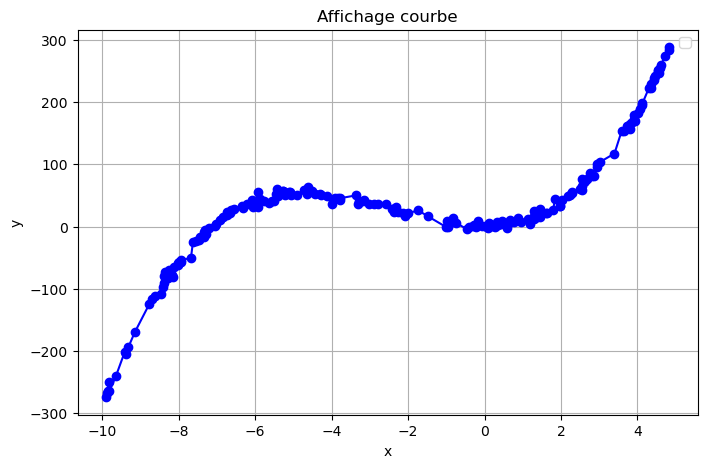

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('secret.csv')

df = df.sort_values(by='x').reset_index(drop=True)

plt.figure(figsize=(8, 5))
plt.plot(df['x'], df['y'], marker='o', linestyle='-', color='b')

plt.title('Affichage courbe')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

In [45]:
import pandas as pd
import tensorflow as tf


df = pd.read_csv('secret.csv')

x_data = tf.constant(df['x'].values, dtype=tf.float32)
y_data = tf.constant(df['y'].values, dtype=tf.float32)

# Variables à rechercher
a = tf.Variable(0.0, dtype=tf.float32)
b = tf.Variable(0.0, dtype=tf.float32)
c = tf.Variable(0.0, dtype=tf.float32)
d = tf.Variable(0.0, dtype=tf.float32)

taux_apprentissage = 0.00001 
nombre_etapes = 1000

# Descente de gradient !
for etape in range(nombre_etapes):
    with tf.GradientTape() as tape:
        y_pred = tf.math.polyval([a, b, c, d], x_data)
        
        # trouvé grâce à l'ia
        perte = tf.reduce_mean((y_data - y_pred)**2)
    
    # Le ruban calcule les 4 dérivées d'un coup en lui passant une liste !
    gradients = tape.gradient(perte, [a, b, c, d])
    grad_a, grad_b, grad_c, grad_d = gradients
    
    a.assign_sub(taux_apprentissage * grad_a)
    b.assign_sub(taux_apprentissage * grad_b)
    c.assign_sub(taux_apprentissage * grad_c)
    d.assign_sub(taux_apprentissage * grad_d)
    
print(f"Coef a : {a}")
print(f"Coef b : {b}")
print(f"Coef c : {c}")
print(f"Coef d : {d}")

Coef a : <tf.Variable 'Variable:0' shape=() dtype=float32, numpy=1.0052611827850342>
Coef b : <tf.Variable 'Variable:0' shape=() dtype=float32, numpy=7.256755828857422>
Coef c : <tf.Variable 'Variable:0' shape=() dtype=float32, numpy=0.6157678961753845>
Coef d : <tf.Variable 'Variable:0' shape=() dtype=float32, numpy=0.3683667480945587>


In [46]:
## Vérifications

In [47]:
n=200
a=1.01
b=7.26
c=0.62
d=0.37
import numpy as np
import matplotlib.pyplot as plt
import csv
f = lambda x:a*x**3+b*x**2+c*x+d
x = 15*np.random.rand(1,n)-10*np.ones((1,n)) #x\in [-10;5] n valeurs
F=np.frompyfunc(f,1,1) #type Object
y=F(x)+np.random.normal(0,5,n)
data=[[x,y] for x,y in zip(np.asarray(x[0]),np.asarray(y[0]))]
with open('data/secret.csv','w',newline='') as csvfile:
    writer = csv.writer(csvfile)
    writer.writerows([['x','y']])
    writer.writerows(data)

/tmp/ipykernel_146448/699476041.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


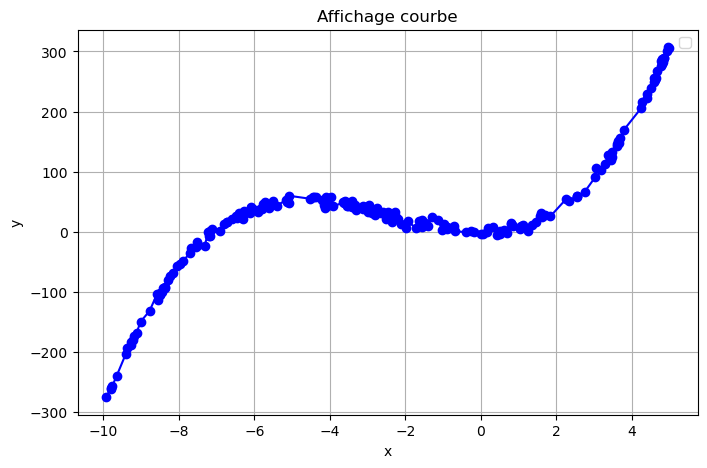

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data/secret.csv')

df = df.sort_values(by='x').reset_index(drop=True)

plt.figure(figsize=(8, 5))
plt.plot(df['x'], df['y'], marker='o', linestyle='-', color='b')

plt.title('Affichage courbe')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

On voit que les 2 courbes sont extremement proche, la descente de gradient à donc bien fonctionné !

# 2 Réseaux convolutifs

In [53]:
#Chargement des biblothèques
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models
import os

#Paramètres
## Taille des mini-lots
batch_size = 32
## Nombre d'époques
epochs = 10
## Taille du vecteur d'entrée
input_shape = (28, 28, 1)

#Récupération des données à l'aide de tensorflow dataset
(train_ds, test_ds), ds_info = tfds.load(
    'mnist',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True,
)

#Préparation des données
def normalize_img(image, label):
    image = tf.cast(image, tf.float32) / 255.0 # Normalisation [0, 1]
    return image, label

train_ds = train_ds.map(normalize_img).cache().batch(batch_size).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.map(normalize_img).batch(batch_size).cache().prefetch(tf.data.AUTOTUNE)

#Création du modèle
model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax') # 10 classes pour les chiffres 0-9
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entraînement du modèle
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=epochs,
    shuffle=False, #Inutile ici, car le mélange a déjà été effectué
)

#Évaluation du modèle
score = model.evaluate(test_ds, verbose=0)
print(f"Précision: {score[1]}, fonction de perte: {score[0]}")

ERROR:asyncio:Task was destroyed but it is pending!
task: <Task pending name='Task-348' coro=<_async_in_context.<locals>.run_in_context() done, defined at /home/rapha/anaconda3/envs/tf/lib/python3.12/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-349' coro=<Kernel.shell_main() running at /home/rapha/anaconda3/envs/tf/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /home/rapha/anaconda3/envs/tf/lib/python3.12/site-packages/zmq/eventloop/zmqstream.py:563]>
/home/rapha/anaconda3/envs/tf/lib/python3.12/site-packages/google/protobuf/json_format.py:590: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  field = fields_by_json_name.get(name, None)
ERROR:asyncio:Task was destroyed but it is pending!
task: <Task pending name='Task-349' coro=<Kernel.shell_main() running at /home/rapha/anaconda3/envs/tf/lib/python3.12/site-packages/ipykernel/kernelbase.py:597> cb=[Task.ta

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 23s 12ms/step - accuracy: 0.9558 - loss: 0.1437 - val_accuracy: 0.9811 - val_loss: 0.0601
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9855 - loss: 0.0473 - val_accuracy: 0.9850 - val_loss: 0.0469
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9903 - loss: 0.0322 - val_accuracy: 0.9874 - val_loss: 0.0364
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9926 - loss: 0.0237 - val_accuracy: 0.9889 - val_loss: 0.0383
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9944 - loss: 0.0174 - val_accuracy: 0.9894 - val_loss: 0.0388
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9958 - loss: 0.0132 - val_accuracy: 0.9891 - val_loss: 0.0425
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9964 - loss: 0.0112 - val_accuracy: 0.9909 - val_loss: 0.0350
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.9973 -

On obtient un taux de précision de 99%
Les lignes 41 à 49 sont les déclarations des différentes couches du réseau de neuronnes
les lignes 44 et 46 permettent la rédction de l'image


In [55]:
score = model.evaluate(train_ds, verbose=0)
print(f"Précision : {score[1]}, fonction de perte : {score[0]}")

Précision : 0.9978333115577698, fonction de perte : 0.006054286379367113


La précision est bien mieux